# Directional Implicit Spring From Spring Data

This notebook generates target geometries with `SpringFF`, perturbs the spring parameters, then recovers them with `DirectionalImplicitMultipleSystemOptimizer`.


In [8]:
import sys
import os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..', '..', '..')))

import copy
import torch
import numpy as np
import matplotlib.pyplot as plt

from geomatry.opt_Energy_approximated.optimizer import DirectionalImplicitMultipleSystemOptimizer
from geomatry.opt.loss import rmsd_loss
from geomatry.ff.graph import get_given_graph_builder
from geomatry.ff.springs import SpringFF, _random_spring_systems, _random_spring_ff_param


In [9]:
def min_pair_distance(Ra: torch.Tensor) -> float:
    Ra = Ra.detach()
    dmat = torch.cdist(Ra, Ra)
    return float(torch.min(dmat + torch.eye(Ra.shape[0], device=Ra.device) * 1e6))


In [10]:
systemN = 20
N = 8
N_pairs = 12
max_Za = 3
fixed_atom_indices = [0,1,2]

Ras, Zas, idx_is, idx_js = _random_spring_systems(systemN, N, N_pairs, max_Za, start_Za=1)
k, r0 = _random_spring_ff_param(max_Za, k_max=2.0, r0_max=1.5)

ff = SpringFF(max_Za)
ff.reset_parameters(k, r0)
params_star = copy.deepcopy(ff.state_dict())

graph_builders = [get_given_graph_builder(idx_i, idx_j) for idx_i, idx_j in zip(idx_is, idx_js)]

print('sample target k', k[1:, 1:].mean().item())
print('sample target r0', r0[1:, 1:].mean().item())
print('sample min distances', [min_pair_distance(Ra) for Ra in Ras[:3]])


sample target k 1.3298326431049847
sample target r0 0.8976790274521007
sample min distances [0.923099292598797, 0.3968643604784504, 1.1354926025057217]


In [11]:
optimizer = DirectionalImplicitMultipleSystemOptimizer(
    Ras, Zas, graph_builders, ff, rmsd_loss,
    params_star=params_star,
    fixed_atom_indices=fixed_atom_indices,
    fmax=1e-5
)

perturbed_k = torch.abs(k.clone() + 0.3 * torch.randn_like(k))
perturbed_r0 = torch.abs(r0.clone() + 0.1 * torch.randn_like(r0))
ff.reset_parameters(perturbed_k, perturbed_r0)
params_0 = copy.deepcopy(ff.state_dict())

print('start k mean', params_0['k'][1:, 1:].mean().item())
print('start r0 mean', params_0['r0'][1:, 1:].mean().item())
print('target k mean', params_star['k'][1:, 1:].mean().item())
print('target r0 mean', params_star['r0'][1:, 1:].mean().item())


start k mean 1.274613243832245
start r0 mean 0.9007154793498025
target k mean 1.3298326431049847
target r0 mean 0.8976790274521007


In [12]:
new_params = optimizer.optimize(params_0, lr=1e-4, epoch=15001, print_period=5000, e_size=0.2, eN=9, sg=2)
print('optimization complete')


  0%|          | 0/15001 [00:00<?, ?it/s]

Iteration 0, total_scale: 2.545896e-01


 33%|███▎      | 5005/15001 [02:18<04:07, 40.42it/s]

Iteration 5000, total_scale: 6.532652e-02


 67%|██████▋   | 10006/15001 [04:35<02:02, 40.66it/s]

Iteration 10000, total_scale: 1.439766e-02


100%|██████████| 15001/15001 [06:53<00:00, 36.28it/s]

Iteration 15000, total_scale: 1.515591e-03
optimization complete


[0.5774886  1.26905034 1.1726203  1.26904996 1.99662559 1.51436782
 1.17262108 1.51436809 1.84214091]


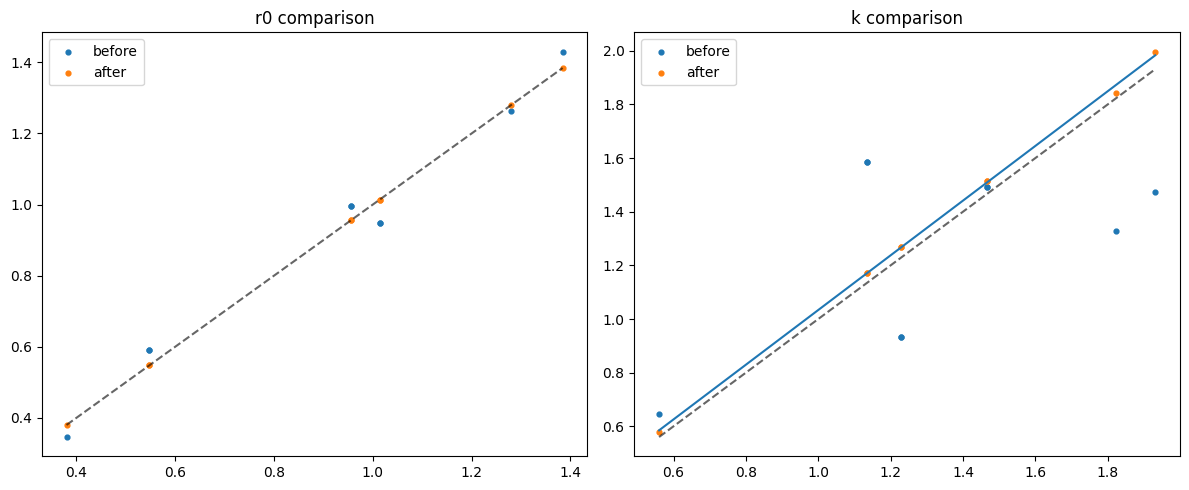

In [13]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
target_r0 = params_star['r0'][1:, 1:].detach().reshape(-1).cpu().numpy()
before_r0 = params_0['r0'][1:, 1:].detach().reshape(-1).cpu().numpy()
after_r0 = new_params['r0'][1:, 1:].detach().reshape(-1).cpu().numpy()
plt.scatter(target_r0, before_r0, label='before', s=12)
plt.scatter(target_r0, after_r0, label='after', s=12)
plt.plot([target_r0.min(), target_r0.max()], [target_r0.min(), target_r0.max()], 'k--', alpha=0.6)
plt.title('r0 comparison')
plt.legend()

plt.subplot(1, 2, 2)
target_k = params_star['k'][1:, 1:].detach().reshape(-1).cpu().numpy()
before_k = params_0['k'][1:, 1:].detach().reshape(-1).cpu().numpy()
after_k = new_params['k'][1:, 1:].detach().reshape(-1).cpu().numpy()
print(after_k)
plt.scatter(target_k, before_k, label='before', s=12)
plt.scatter(target_k, after_k, label='after', s=12)
plt.plot([target_k.min(), target_k.max()], [target_k.min(), target_k.max()], 'k--', alpha=0.6)
plt.title('k comparison')
plt.legend()
# Linear fits: y = a*x + b
def add_linear_fit(x, y, label, linestyle='-'):
    mask = np.isfinite(x) & np.isfinite(y)
    x_fit_data = x[mask]
    y_fit_data = y[mask]

    a, b = np.polyfit(x_fit_data, y_fit_data, 1)
    y_pred = a * x_fit_data + b

    r2 = 1 - np.sum((y_fit_data - y_pred)**2) / np.sum((y_fit_data - y_fit_data.mean())**2)

    x_line = np.linspace(x_fit_data.min(), x_fit_data.max(), 200)
    y_line = a * x_line + b

    plt.plot(
        x_line, y_line, linestyle,
        label=f'{label} fit: y={a:.3f}x+{b:.3f}, R²={r2:.3f}'
    )

add_linear_fit(target_k, after_k, 'after')
plt.tight_layout()
